
# Autoencoders & VAEs as Regression — the Swiss Roll

The MNIST notebook framed AEs/VAEs around **images**: high-dimensional,
pixel values bounded to `[0,1]`, reconstructions scored with binary
cross-entropy, digit labels used only for coloring plots.

This notebook is the deliberate opposite case, designed to round out your
understanding: **low**-dimensional, **unbounded**, continuous data, scored
with plain **MSE** — which is the more general, more common setting for
autoencoders outside of image pixels. Same models, same code patterns,
different data — which is exactly the point: if the patterns below feel
familiar, that's a good sign the concepts (not just the MNIST-specific
details) landed.

## The dataset: a 2D swiss roll

We'll use `sklearn.datasets.make_swiss_roll`, viewed from above so it
collapses into a 2D spiral, with Gaussian noise scattering points off the
true curve. A binary label (which half of the spiral a point sits on) comes
along for free, for plot coloring only — never used in training, same as
MNIST's digit labels.

## The framing: reconstruction *as regression*

With a **1-dimensional bottleneck**, an autoencoder trained on this data is
doing something very concrete: finding the single best 1D curve that
threads through a noisy 2D point cloud — learning the identity function
$f(x) \approx x$, but forced through a narrow enough bottleneck that it
can't just memorize each point; it has to find the underlying structure.
That's a regression problem in a very literal sense, and because everything
here is 2D or 1D, you can **see the learned curve directly** — something
that was impossible with 784-pixel MNIST digits.

**Learning objectives:**
- Reuse your AE/VAE building blocks on continuous, unbounded data — and see
  concretely *why* the decoder here has no `Sigmoid` and the loss is MSE,
  not BCE
- Visualize a trained model's bottleneck as an actual regression curve,
  compared against a linear (PCA) baseline
- See how a VAE's 1D latent distribution compares to its prior directly, via
  a histogram instead of a high-dimensional scatter plot
- Test whether an unsupervised bottleneck — trained with no label anywhere
  in its loss — nonetheless preserves enough structure to distinguish the
  spiral's two halves, and see why a *linear* classifier and a *nonlinear*
  one can tell very different stories about the same latent space
- Get a feel for how noise/stochasticity in the data interacts with a
  bottleneck — why compression acts like a smoother, not an interpolator

Same rules as before: `# TODO` markers are yours to fill in, sanity-check
cells verify you're on track, no solutions are given.



## 0. Setup


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

%matplotlib inline

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")



### Hyperparameters

Note `LATENT_DIM = 1` — this is deliberate, not a simplification for
convenience. A 1D bottleneck on 2D data forces the model to find *the*
curve, and lets us visualize it directly by sweeping over every possible
latent value and decoding it.


In [ ]:

N_SAMPLES = 2000
NOISE = 0.5          # try changing this later — see Section 8

BATCH_SIZE = 64
INPUT_DIM = 2
HIDDEN_DIM = 128
LATENT_DIM = 1        # deliberately 1D — see note above
EPOCHS = 500
LR = 1e-3



## 1. Data: a 2D swiss roll

`make_swiss_roll` actually returns 3D points lying on a rolled-up sheet; we
keep only 2 of the 3 coordinates, which collapses it into a 2D spiral (the
dropped axis is just the "height" of the roll and carries no structure worth
keeping here). It also returns `t`, each point's position *along* the
spiral — a continuous value we'll use to derive a binary label, purely for
plot coloring.

We also **standardize** the coordinates (zero mean, unit variance) before
doing anything else. This wasn't necessary for MNIST — pixels already arrive
in a small, consistent `[0,1]` range — but raw swiss-roll coordinates span
a much wider, off-center range, and unnormalized inputs like that routinely
slow down or destabilize neural network training. Standardizing first is
standard practice for basically any non-image tabular/continuous data.

This part is boilerplate, given in full.


In [ ]:

X_3d, t = make_swiss_roll(n_samples=N_SAMPLES, noise=NOISE, random_state=SEED)
X_raw = X_3d[:, [0, 2]]                          # drop the height axis -> 2D spiral
labels = (t > np.median(t)).astype(int)          # binary split, for coloring only

X_mean, X_std = X_raw.mean(axis=0), X_raw.std(axis=0)
X = (X_raw - X_mean) / X_std                     # standardize once, use everywhere below

X_train, X_test, t_train, t_test, y_train, y_test = train_test_split(
    X, t, labels, test_size=0.2, random_state=SEED
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], c=t, cmap="viridis", s=8)
axes[0].set_title("colored by position along the spiral (t)")
axes[1].scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=8)
axes[1].set_title("colored by binary label (median split of t)")
for ax in axes:
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()



### Your task: wrap the data in a `DataLoader`

MNIST came with `torchvision` handling this; here we build it ourselves from
a plain numpy array.

1. Convert `X_train` to a `torch.FloatTensor`.
2. Wrap it in a `TensorDataset`. `TensorDataset` needs at least one tensor,
   but conventionally pairs data with a target — since we're reconstructing
   the input itself (there's no separate label to predict), pass the same
   tensor twice: `TensorDataset(X_tensor, X_tensor)`. This isn't just a
   workaround — it's a literal statement of the task: *the input is its own
   target*, i.e. the identity function.
3. Wrap that in a `DataLoader` with `batch_size=BATCH_SIZE, shuffle=True`.

Do the same for `X_test` (`shuffle=False` for test data, by convention).


In [ ]:

# TODO: build train_loader and test_loader from X_train / X_test
train_loader = None
test_loader = None


In [ ]:

# Sanity check
xb, yb = next(iter(train_loader))
assert xb.shape == (BATCH_SIZE, INPUT_DIM) or xb.shape[0] <= BATCH_SIZE
assert torch.equal(xb, yb), "the dummy target should be identical to the input"
print("DataLoader looks correct. Batch shape:", xb.shape)



## 2. A linear baseline: PCA

Before training anything nonlinear, it's worth seeing what the *linear*
version of "compress to 1D, then reconstruct" looks like — that's exactly
what PCA with 1 component does. It'll give us something concrete to compare
the AE and VAE against later.

Given in full — no task here, just run it and look at the plot.


In [ ]:

pca = PCA(n_components=1)
z_pca = pca.fit_transform(X_train)
X_pca_recon = pca.inverse_transform(z_pca)

# Sweep across the 1D PCA component to draw its reconstruction as a line
z_sweep = np.linspace(z_pca.min(), z_pca.max(), 200).reshape(-1, 1)
line_pca = pca.inverse_transform(z_sweep)

plt.figure(figsize=(6, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c="lightgray", s=8, label="data")
plt.plot(line_pca[:, 0], line_pca[:, 1], color="crimson", linewidth=2.5, label="PCA (linear)")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("A straight line is the best a *linear* bottleneck can do")
plt.show()



Keep this plot in mind — a straight line is the best any *linear* method can
do here, no matter how it's fit. The spiral's actual structure is curved, so
this is a hard ceiling on PCA's reconstruction quality. A nonlinear
autoencoder has no such restriction.



## 3. Autoencoder (AE)

### Theory: same architecture, different output layer

The encoder/decoder shape is identical to the MNIST notebook:

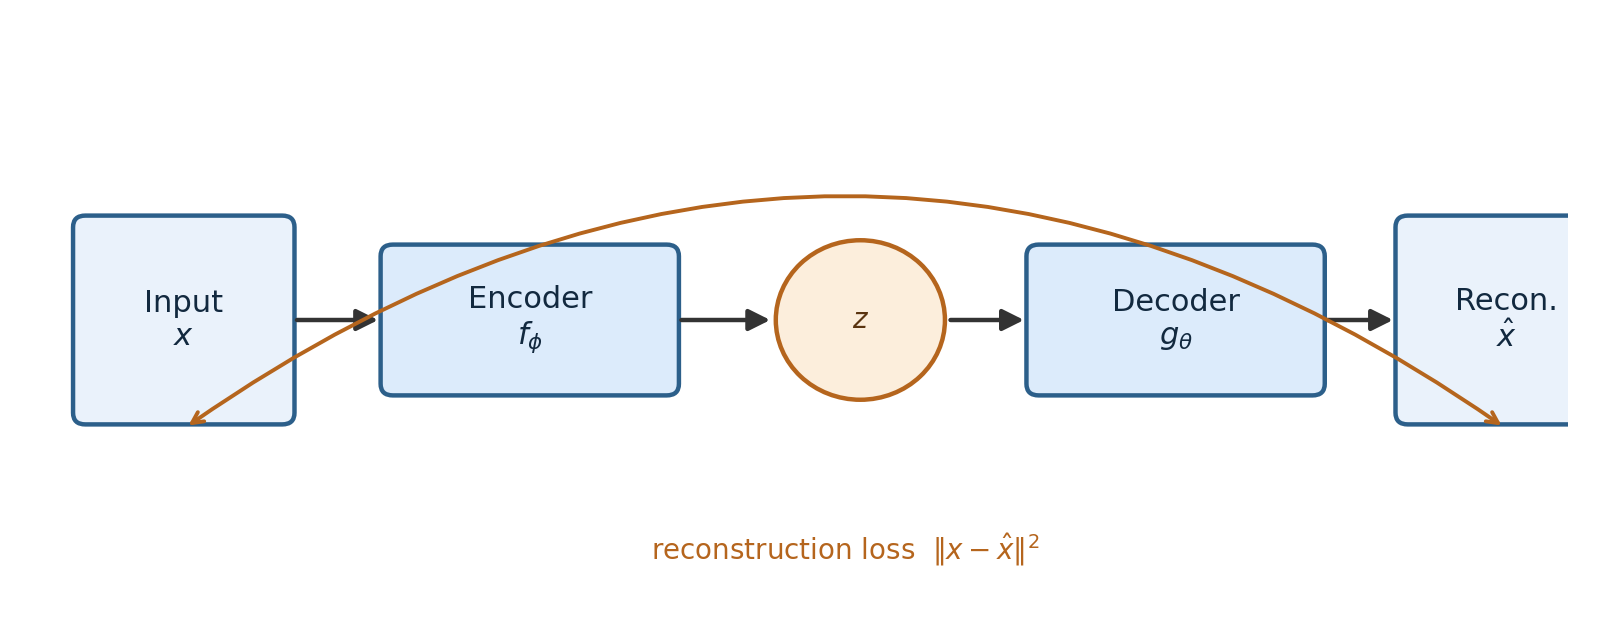

$$
\mathcal{L}_{\text{AE}}(\theta, \phi) = \frac{1}{N}\sum_{i=1}^{N} \left\lVert x_i - g_\theta\big(f_\phi(x_i)\big) \right\rVert_2^2
$$

But look closely at what changes:

> **No `Sigmoid` on the decoder's output this time.** `Sigmoid` exists to
> squash outputs into `[0,1]` to match pixel intensities and to satisfy BCE's
> requirement that its inputs be strictly between 0 and 1. Our swiss roll
> coordinates are unbounded, ordinary real numbers — nothing constrains them
> to any particular range, so nothing should squash the decoder's output.
> The very last layer is just a plain `nn.Linear`, full stop.
>
> **MSE, not BCE.** Squared error is what the general AE objective is
> written in terms of, and there's no probabilistic pixel-intensity
> interpretation to justify BCE here. MSE is simply "how far is the
> reconstructed point from the real point," which is exactly what we want
> to measure for continuous coordinates.

Everything else — the encoder compressing to a bottleneck, the decoder
expanding back out, training by gradient descent — is unchanged.



### Your task: implement `Encoder`, `Decoder`, `Autoencoder`

Same shapes as the MNIST notebook, with `INPUT_DIM = 2` and
`LATENT_DIM = 1` this time:

- `Encoder`: `Linear(input_dim, hidden_dim)` → `ReLU` → `Linear(hidden_dim, latent_dim)`
- `Decoder`: `Linear(latent_dim, hidden_dim)` → `ReLU` → `Linear(hidden_dim, output_dim)`
  — **no activation after the last layer.**
- `Autoencoder`: wires the two together, `forward(x)` returns `x_hat`.


In [ ]:

class Encoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        # TODO
        raise NotImplementedError

    def forward(self, x):
        # TODO
        raise NotImplementedError


class Decoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, hidden_dim=HIDDEN_DIM, output_dim=INPUT_DIM):
        super().__init__()
        # TODO — remember: no final activation
        raise NotImplementedError

    def forward(self, z):
        # TODO
        raise NotImplementedError


class Autoencoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        # TODO
        raise NotImplementedError

    def forward(self, x):
        # TODO
        raise NotImplementedError


In [ ]:

# Sanity check
ae = Autoencoder().to(device)
dummy_x = torch.randn(4, INPUT_DIM).to(device)   # note: randn, not rand — unbounded now
dummy_x_hat = ae(dummy_x)

assert dummy_x_hat.shape == dummy_x.shape
assert torch.isfinite(dummy_x_hat).all(), "output contains NaN/inf — check your layers"
print("Autoencoder shapes look correct. Sample output:", dummy_x_hat[0].detach().cpu().numpy())



### Your task: the AE training loop

Same three pieces as before: forward pass + MSE loss, then
`zero_grad` / `backward` / `step`. No flattening needed this time — `x` is
already a plain `(batch, 2)` tensor. Use `F.mse_loss(x_hat, x)` (default
`reduction='mean'` — note this divides by *all* elements, batch and
features both, unlike the sum-then-divide-by-batch-size convention used for
images; for a loss this simple, plain mean is the standard choice).


In [ ]:

ae = Autoencoder().to(device)
optimizer = torch.optim.Adam(ae.parameters(), lr=LR)

ae_train_losses = []

for epoch in range(EPOCHS):
    epoch_loss = 0.0
    n_batches = 0
    for x, _ in train_loader:
        x = x.to(device)
        # TODO: forward pass + MSE loss
        loss = None  # replace this

        # TODO: zero_grad, backward, step

        epoch_loss += loss.item()
        n_batches += 1

    epoch_loss /= n_batches
    ae_train_losses.append(epoch_loss)
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} — AE loss: {epoch_loss:.4f}")


In [ ]:

plt.plot(ae_train_losses)
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Autoencoder training loss")
plt.show()



### Your task: visualize reconstructions

Run `X_test` through the trained `ae` and scatter-plot the **original test
points** and their **reconstructions** on the same axes, in two different
colors, with a legend. Don't forget `.detach().cpu().numpy()` before
plotting.


In [ ]:

# TODO: reconstruct X_test through ae and plot original vs. reconstructed points



## 4. The payoff: visualizing the learned curve directly

Because `LATENT_DIM = 1`, the decoder is a function from a single number to
a 2D point — exactly like the PCA line you plotted in Section 2, except
potentially curved instead of straight.

### Your task

1. Encode all of `X_train` to get their latent codes `z` (you'll need this
   to know what range of `z` values the model actually learned to use).
2. Build `z_sweep = np.linspace(z.min(), z.max(), 200).reshape(-1, 1)`,
   convert to a tensor, and decode it through `ae.decoder`.
3. Plot the swiss roll scatter (light gray, like the PCA plot) with this
   decoded curve drawn over it in a bold color.

**Compare this plot to your PCA plot from Section 2.** If training went
well, you should see the AE's curve actually bend to follow the spiral,
where PCA was forced to stay straight.


In [ ]:

# TODO: sweep the AE's learned 1D latent space and plot the resulting curve
# over the data, for comparison against the PCA line above



### Your task: does the latent code recover the spiral's true position?

The dataset came with `t_train` — each point's true position along the
spiral, which the model never saw during training. Scatter-plot the AE's
encoded `z` (x-axis) against `t_train` (y-axis) for the training set.

**Go in with calibrated expectations here.** In principle, a 1D code that
reconstructs the spiral well should track `t` in some consistent (if not
necessarily linear) order. In practice, gradient descent only ever promised
to minimize reconstruction error — it has no incentive to find the
*cleanest* possible parametrization, only *a* low-error one. You may see a
fairly clean monotonic trend, or you may see something noisier or partially
tangled, even with a curve that visually tracks the spiral well in Section
4's plot. Both outcomes are worth sitting with: a clean result shows the
bottleneck recovered the manifold's natural coordinate; a messy one is a
real, common illustration of the gap between "minimizes the loss" and
"finds the most interpretable solution" — a gap that shows up constantly in
deep learning and is worth being able to recognize.


In [ ]:

# TODO: scatter z (encoded from X_train) against t_train



## 5. Variational Autoencoder (VAE)

### Theory: the Gaussian decoder, made concrete

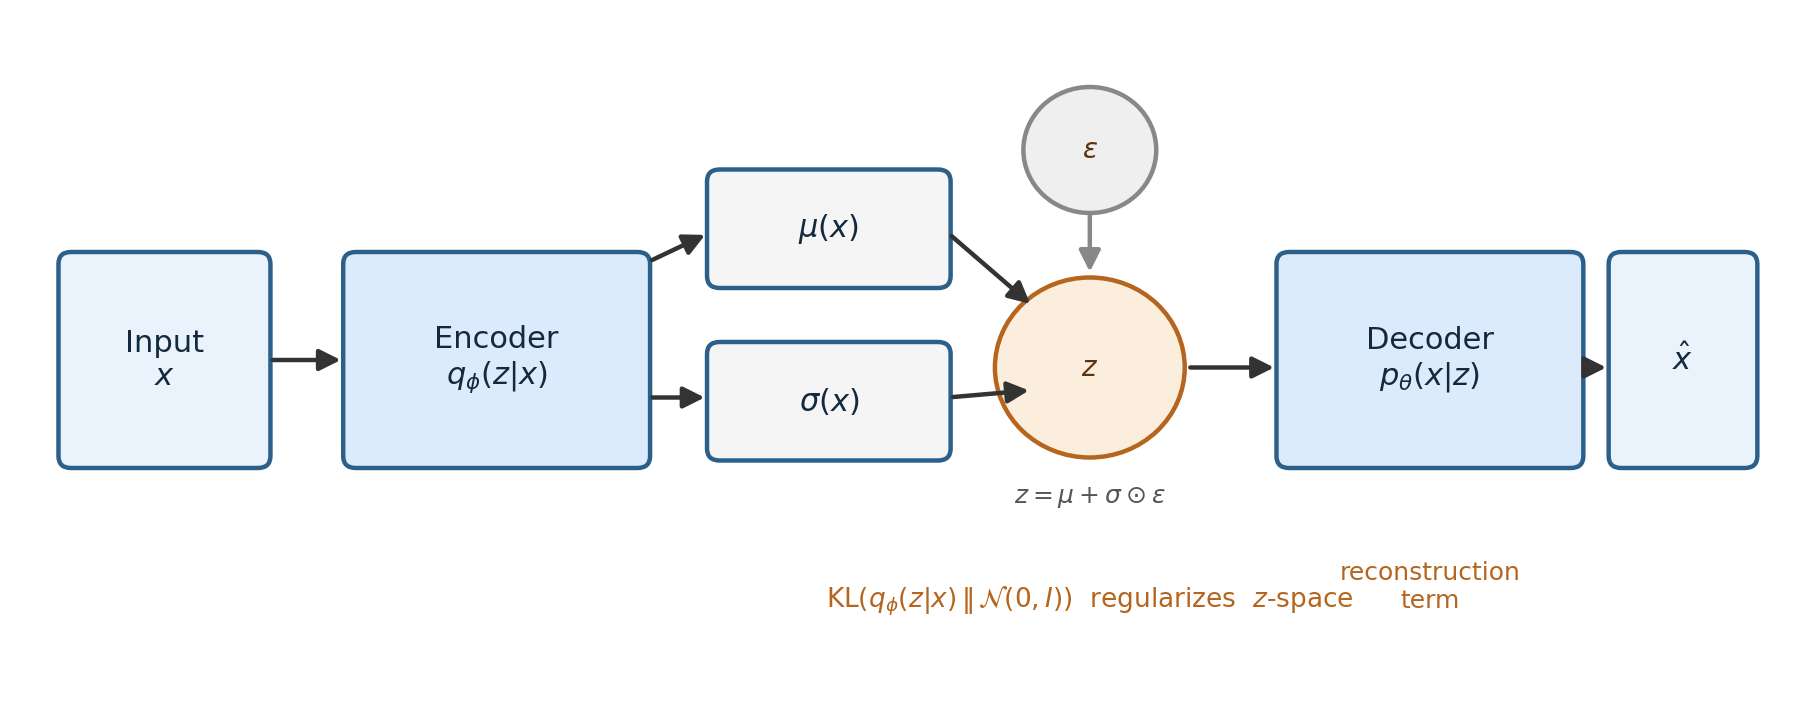

$$
\mathcal{L}_{\text{VAE}} = \underbrace{-\,\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x\mid z)\big]}_{\text{reconstruction term}} \;+\; \underbrace{D_{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{regularization term}}
$$

$$
D_{KL} = \frac{1}{2}\sum_{j=1}^{k}\Big(\mu_j^2 + \sigma_j^2 - \log \sigma_j^2 - 1\Big)
$$

In the MNIST notebook, the reconstruction term became binary cross-entropy
because pixels were treated as Bernoulli-distributed. Here, there's no such
assumption to make — the natural choice is a **Gaussian** decoder
distribution, $p_\theta(x\mid z) = \mathcal{N}(g_\theta(z), I)$, and under a
Gaussian with fixed variance, $-\log p_\theta(x\mid z)$ reduces (up to an
additive constant that doesn't affect gradients) to exactly:

$$
\lVert x - g_\theta(z) \rVert_2^2
$$

— plain MSE. This is the same general ELBO as before; only the assumed
shape of the decoder's output distribution changed, and that choice is what
determined the loss function in both notebooks. Everything about
`reparameterize` and the KL term is completely unchanged from MNIST.



### Your task: implement `VAEEncoder`, `reparameterize`, `VAE`, `vae_loss`

Same structure as the MNIST notebook:

- `VAEEncoder`: shared trunk `Linear(input_dim, hidden_dim)` → `ReLU`, then
  two heads `Linear(hidden_dim, latent_dim)` for `mu` and for `logvar`.
- `reparameterize(mu, logvar)`: $z = \mu + \sigma \odot \epsilon$, with
  `std = torch.exp(0.5 * logvar)` and `eps = torch.randn_like(std)`.
- `VAE`: wires `VAEEncoder` → `reparameterize` → `Decoder` (reuse the
  `Decoder` class you already wrote — it doesn't change for a VAE).
  `forward(x)` returns `x_hat, mu, logvar`.
- `vae_loss(x_hat, x, mu, logvar)`: MSE reconstruction term (use
  `reduction='sum'` here, then divide by batch size, so it's on a comparable
  scale to the summed KL term below — unlike the plain-mean AE loss above)
  plus the closed-form KL term (summed over latent dims, divided by batch
  size). Return `recon_loss, kl_loss, total_loss`.


In [ ]:

class VAEEncoder(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        # TODO
        raise NotImplementedError

    def forward(self, x):
        # TODO
        raise NotImplementedError


def reparameterize(mu, logvar):
    # TODO
    raise NotImplementedError


class VAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        # TODO
        raise NotImplementedError

    def forward(self, x):
        # TODO
        raise NotImplementedError


def vae_loss(x_hat, x, mu, logvar):
    batch_size = x.size(0)
    # TODO: recon_loss (MSE, summed, divided by batch_size)
    # TODO: kl_loss (closed-form formula, summed over latent dims, divided by batch_size)
    total_loss = None  # TODO
    return recon_loss, kl_loss, total_loss


In [ ]:

# Sanity checks
mu_test = torch.zeros(200, LATENT_DIM)
logvar_test = torch.full((200, LATENT_DIM), -10.0)
z_test = reparameterize(mu_test, logvar_test)
assert z_test.shape == mu_test.shape
assert torch.allclose(z_test, mu_test, atol=0.05)

vae = VAE().to(device)
dummy_x = torch.randn(4, INPUT_DIM).to(device)
x_hat, mu, logvar = vae(dummy_x)
assert x_hat.shape == dummy_x.shape
assert mu.shape == (4, LATENT_DIM)
assert logvar.shape == (4, LATENT_DIM)

print("VAE components look correct.")



### Your task: the VAE training loop

Same pattern as the MNIST notebook's VAE loop — track `recon_loss` and
`kl_loss` separately (not just their sum), for the same posterior-collapse
monitoring reason covered there.


In [ ]:

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=LR)

vae_recon_losses = []
vae_kl_losses = []

for epoch in range(EPOCHS):
    epoch_recon = 0.0
    epoch_kl = 0.0
    n_batches = 0
    for x, _ in train_loader:
        x = x.to(device)
        # TODO: forward pass -> x_hat, mu, logvar
        # TODO: compute recon_loss, kl_loss, loss via vae_loss(...)
        # TODO: zero_grad, backward, step

        epoch_recon += recon_loss.item()
        epoch_kl += kl_loss.item()
        n_batches += 1

    epoch_recon /= n_batches
    epoch_kl /= n_batches
    vae_recon_losses.append(epoch_recon)
    vae_kl_losses.append(epoch_kl)
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} — recon: {epoch_recon:.4f}, KL: {epoch_kl:.4f}")


In [ ]:

plt.plot(vae_recon_losses, label="reconstruction")
plt.plot(vae_kl_losses, label="KL")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("VAE training loss (tracked separately)")
plt.show()



## 6. The VAE's curve, and generating along it

### Your task: plot the VAE's learned curve

Same exercise as Section 4, but using `vae.encoder` (use `mu`, not a random
sample — see the MNIST notebook's reasoning) to find the observed latent
range, and `vae.decoder` to decode the sweep.


In [ ]:

# TODO: sweep the VAE's learned 1D latent space (via mu) and plot the curve over the data



### Your task: generate new points from the prior

Unlike the AE, the VAE's latent space is explicitly regularized toward
$\mathcal{N}(0, I)$ — so you don't need to check the observed range first.
Sample `z ~ N(0,1)` directly (shape `(200, 1)`), decode, and scatter the
results over the real data. If training went well, generated points should
land convincingly along the spiral, not scattered randomly across the plot.


In [ ]:

# TODO: sample z ~ N(0,1), decode through vae.decoder, plot over the real data



### Your task: does the latent distribution actually match the prior?

Since `LATENT_DIM = 1`, you can check this directly with a histogram — no
dimensionality reduction needed, unlike MNIST's 2D scatter approach.

1. Encode all of `X_train` to get `mu` values (one per point).
2. Plot a histogram of these `mu` values (`density=True` so it's on the same
   scale as a probability density).
3. Overlay the standard normal density on top:
   `from scipy.stats import norm` then `plt.plot(xs, norm.pdf(xs))` for a
   range of `xs` spanning your histogram's x-axis.

A reasonably good match (bell-shaped, roughly centered at 0, roughly unit
width) is exactly the KL term doing its job. A sharp spike at 0 instead would
be posterior collapse — the failure mode from the MNIST notebook, now
directly visible in 1D instead of inferred from a KL loss curve.


In [ ]:

# TODO: histogram of encoded mu values, with a standard normal density overlaid



## 7. Do the latent codes separate the two spiral halves?

Recall `labels` — literally just "which half of the unrolled spiral," from
median-splitting `t`. Neither the AE nor the VAE ever saw `labels` during
training; the entire objective was reconstruction. So: does an unsupervised
bottleneck, trained only to reconstruct, happen to preserve enough
information to tell the two halves apart anyway?

### Your task: a first visual gut-check

For the AE, plot **two overlapping histograms** of `z` (the training-set
latent codes from Section 4) — one for points where `y_train == 0`, one for
`y_train == 1` — on the same axes, with a legend and some transparency
(`alpha=0.5`) so both are visible. Repeat for the VAE's `mu` values.


In [ ]:

# TODO: two overlapping histograms of z, split by y_train — one for AE, one for VAE



### Your task: quantify it with a classifier

A histogram tells you roughly whether the classes overlap, but not how
separable they really are. Fit a classifier directly on the AE's latent
codes and check its accuracy on **held-out** codes (`X_test`'s encoded `z`,
never seen during that classifier's fitting):

1. Encode `X_train` and `X_test` through `ae.encoder` to get `z_train`,
   `z_test` (as numpy arrays).
2. Fit `sklearn.linear_model.LogisticRegression()` on `(z_train, y_train)`,
   then `.score(z_test, y_test)`.
3. Fit `sklearn.neighbors.KNeighborsClassifier(n_neighbors=5)` the same way.
4. Compare both scores to the trivial baseline of always guessing the
   majority class: `max(y_test.mean(), 1 - y_test.mean())`.

**A genuine possibility worth being ready for:** the logistic regression
score can come out *at or below* the majority baseline. That's not
necessarily a bug in your code — a linear classifier can only cut the
latent space with a single straight threshold, and if Section 4's z-vs-t
plot came out looking folded rather than cleanly monotonic (a real
possibility flagged there), no single threshold on `z` will separate the
classes well, even if the classes are perfectly distinguishable by *some*
rule. That's exactly what the KNN classifier checks for next — it looks at
each point's *local* neighborhood in `z` rather than committing to one
global cut, so it can pick up structure a straight-line classifier can't.
If KNN clearly beats the baseline while logistic regression doesn't, that
gap is itself the finding: class information got preserved in the
bottleneck, just not in a linearly-organized way.


In [ ]:

# TODO: encode X_train/X_test, fit LogisticRegression and KNeighborsClassifier
# on the AE's z, and compare both accuracies to the majority-class baseline



### Your task (bonus): does a 2D latent space make it linear?

Go back to the hyperparameters cell, set `LATENT_DIM = 2`, and re-run the AE
class definitions, sanity check, and training loop cells (VAE too, if you
like). Then:

1. Produce a 2D scatter plot of `z` (from the retrained AE), colored by
   `y_train` — the same kind of plot as the MNIST notebook's Section 3,
   just with 2 classes instead of 10 digits this time.
2. Re-run the logistic regression check from above on this new 2D `z`.

With one extra latent dimension, does a straight line now separate the two
colors reasonably well in the scatter plot? Does the logistic regression
score move noticeably closer to (or past) the KNN score from the 1D case?
Reducing back to `LATENT_DIM = 1` afterward will let the rest of the
notebook's cells (which assume a 1D bottleneck for the curve-sweeping plots)
keep working correctly.


In [ ]:

# TODO (bonus): retrain with LATENT_DIM = 2, plot the 2D latent scatter colored
# by class, and re-check logistic regression accuracy



## 8. Bonus: all three curves at once

Put the PCA line, the AE curve, and the VAE curve on a single plot, over the
same scatter of real data, each in a different color with a legend. This is
the single clearest summary this notebook can produce: a straight line
(linear, PCA) versus two learned nonlinear curves (AE, VAE) attempting the
same 1D-bottleneck regression task.


In [ ]:

# TODO (bonus): overlay the PCA line, AE curve, and VAE curve on one plot



## 9. Bonus: what does the bottleneck do with noise?

Go back to Section 1 and change `NOISE` — try `0.1` (much cleaner spiral)
and `1.5` (much noisier) — then re-run the whole notebook top to bottom for
each value.

**What to look for:** a bottlenecked model can't memorize every noisy point
individually (that's the entire point of the bottleneck), so it's forced to
find a single smooth curve that reasonably explains *all* the noisy points
at once. This is precisely what a regression line does with noisy 1D
data — it doesn't zigzag through every point, it smooths through them. Watch
whether the learned curve tracks the noise (bad — this would suggest the
bottleneck isn't constraining enough, or training has run too long) or
stays smooth and central through the noisy scatter (expected, and a nice
concrete demonstration of the bottleneck acting as a regularizer).



## 10. Where this leaves you

Between this notebook and the MNIST one, you've now implemented the same AE
and VAE building blocks under two genuinely different data regimes:

| | MNIST notebook | This notebook |
|---|---|---|
| Data | high-dim, pixels in `[0,1]` | low-dim, unbounded coordinates |
| Decoder output layer | `Sigmoid` | none (plain `Linear`) |
| Reconstruction loss | BCE | MSE |
| What the bottleneck buys you | compression, generation | a literal, visualizable regression curve |
| Latent space check | 2D scatter plot | 1D histogram vs. the prior |
| Class information | 10 digit classes, for coloring only | 2 spiral-half classes — you tested this directly in Section 7 |

If the code in this notebook felt more like "the same thing again" than
"something new to learn," that's the intended outcome — the underlying
mechanics (encoder/decoder shape, reparameterization, the ELBO, the training
loop) don't actually depend on images at all. Everything image-specific in
the MNIST notebook was a detail sitting on top of that same core.

Section 7 is worth reflecting on a bit more: a purely unsupervised
reconstruction objective ended up preserving real class-relevant structure,
recoverable by a nonlinear classifier even when a linear one struggled. This
"classes fall out of unsupervised structure, unrequested" pattern is worth
recognizing — it shows up again and again in representation learning well
beyond this toy example.
